# Energy consumption in Brussels
Yearly energy consumption is quite easy to learn from the billing issued by the energy providers.
Sibelga publishes the yearly consumption for the Brussels region. Looking at the residential data, we can see that the average yearly consumption per household is around 2000 kWh, with some geographical difference: 

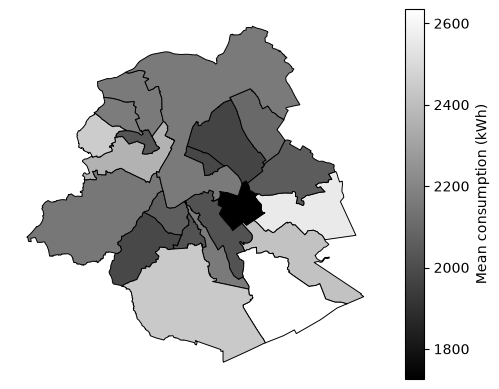

In [10]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df_consumption = pd.read_csv("../data/202512-yearly-consumption-elec-2025.csv", sep=";", decimal=".")
df_consumption_res = df_consumption[df_consumption['CUSTOMER_TYPE_FR_TX'] == 'RES']
df_consumption_res['CITY_FR_TX'] = df_consumption_res['CITY_FR_TX'].replace(r"Brux.*", "Bruxelles", regex=True)
df_consumption_res['AVERAGE_KWH'] = df_consumption_res['VOLUME_KWH'] / df_consumption_res['COUNT_EAN']
mean_cons = df_consumption_res.groupby('CITY_FR_TX')['AVERAGE_KWH'].mean().sort_values(ascending=False)

# Load a polygon layer containing the Brussels municipalities.
municipalities = gpd.read_file("../data/limites-administratives-des-communes-en-region-de-bruxelles-capitale.geojson")
results = mean_cons.rename("mean_kwh").rename_axis("CITY_FR_TX").reset_index()
map_data = municipalities.merge(results, left_on="name_fr", right_on="CITY_FR_TX", how="left")

ax = map_data.plot(column="mean_kwh", cmap="gray", legend=True, edgecolor="black", linewidth=0.7, missing_kwds={"color": "lightgrey", "label": "No data"}, legend_kwds={"label": "Mean consumption (kWh)"})
ax.set_axis_off()
fig = ax.get_figure()
plt.show()

The municipalities consuming a larger share of energy are the ones on the south: Woluwe-Saint-Pierre, Auderghem, Watermael-Boitsfort, Uccle, which also happen to be the richest municipalities. 